# `tl.co_occurrence` vs `squidpy.gr.co_occurrence`

Both compute an annular (not cumulative) co-occurrence probability ratio: for
each distance ring, how enriched is type B around type A relative to B's
baseline rate. squidpy's `interval` array is a sequence of bin *edges*, so
this notebook prepends `0.0` to astrolabe's thresholds before passing them to
squidpy, so both tools describe the identical set of bins.

`tl.co_occurrence` previously normalized each type's ring-local rate against
its *global* frequency across the whole dataset, which made the result
asymmetric in `(A, B)`. It now normalizes against each type's *ring-local*
marginal, matching squidpy's convention, so expect a strong, largely
symmetric correlation.


In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import time
import numpy as np
import astrolabe as ab
import squidpy as sq

mdata = ab.datasets.xenium_tiny()
ab.pipeline.filter_xenium(mdata)
ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)
ab.pp.highly_variable_genes(mdata)
ab.tl.pca(mdata)
ab.tl.transcriptional_neighbors(mdata)
ab.tl.cluster(mdata, resolution=0.5)
ab.tl.spatial_neighbors(mdata)

adata = mdata["xenium"]

# Fairness step: copy astrolabe's own spatial graph into the obsp key
# squidpy expects, so both tools permute/aggregate over the *identical*
# graph topology rather than two independently-built ones.
adata.obsp["spatial_connectivities"] = adata.obsp["spatial_neighbors_connectivities"].copy()
adata


INFO:astrolabe.pl._theme:Registered bundled Inter font files with matplotlib


INFO:astrolabe.pl._theme:astrolabe plot theme set to 'light'


INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\squidpy\.astrolabe_cache\datasets\xenium_tiny\outs


C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\io\_xenium.py:870: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  adata.obsm[obsm_key] = ak.Array(
INFO:astrolabe.io._xenium:Loaded 358 cells × 520 features (115 control probes)


INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\squidpy\.astrolabe_cache\datasets\xenium_tiny\outs\transcripts.parquet


...

INFO:astrolabe.pipeline:filter_xenium: done — 328 cells × 255 genes


INFO:astrolabe.tl._graph:transcriptional_neighbors: 328 cells -> uns['neighbors']


INFO:astrolabe.tl._cluster:cluster (leiden, res=0.50): 4 clusters


INFO:astrolabe.tl._graph:spatial_neighbors: 328 cells, 5670 edges (mean degree 17.3) [generic]


AnnData object with n_obs × n_vars = 328 × 255
    obs: 'cell_area', 'nucleus_area', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'nucleus_count', 'unassigned_codeword_total', 'deprecated_codeword_total', 'genomic_control_probe_total', 'negative_control_codeword_total', 'negative_control_probe_total', 'any_negative_control_probe_total', 'n_unassigned_codewords', 'n_deprecated_codewords', 'n_genomic_control_probes', 'n_negative_control_codewords', 'n_negative_control_probes', 'n_any_negative_control_probes', 'pct_unassigned_codewords', 'pct_deprecated_codewords', 'pct_genomic_control_probes', 'pct_negative_control_codewords', 'pct_negative_control_probes', 'pct_any_negative_control_probes', 'pct_counts_control', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'nucleus_to_cell_area_ratio', 'has_nucleus', 'total_counts_norm', 'leiden'

## Dataset and a shared graph

`ab.datasets.xenium_tiny()`, QC'd, normalized, clustered (Leiden), with
astrolabe's own spatial graph copied into `obsp['spatial_connectivities']` -
the key `squidpy.gr.*` looks for by default. Without this step the two tools
would each build their own KNN graph independently and any disagreement
could just be graph-construction noise, not a real difference in the
statistic itself.


## Astrolabe: `tl.co_occurrence`


In [2]:
# xenium_tiny's tissue slice spans roughly 135 x 245 um -- an interval
# reaching out to 300um would put the outer bins beyond the tissue's own
# extent (zero pairs found, a degenerate all-zero ring rather than a
# meaningful "no association" signal), so the upper bound here is chosen to
# stay within real tissue extent instead of astrolabe's own 500um default.
interval = (5.0, 100.0, 20)
_t0 = time.perf_counter()
ab.tl.co_occurrence(mdata, "leiden", interval=interval)
t_astro_s = time.perf_counter() - _t0
print(f"astrolabe runtime: {t_astro_s:.4f}s")
occ_astro = adata.uns["co_occurrence"]["occ"]
thresholds_astro = adata.uns["co_occurrence"]["interval"]
groups_astro = adata.uns["co_occurrence"]["groups"]
occ_astro.shape


INFO:astrolabe.tl._neighborhood:co_occurrence: 4 cell types, 20 distance thresholds.


astrolabe runtime: 0.0047s


(4, 4, 20)

## Reference: `squidpy.gr.co_occurrence`, with a 0-prepended interval array

`np.concatenate([[0.0], thresholds_astro])` makes squidpy's `v_radium[1:]`
equal to astrolabe's own `thresholds` exactly, so both describe the
identical set of bin edges before comparing.


In [3]:
interval_sq = np.concatenate([[0.0], thresholds_astro])
_t0 = time.perf_counter()
occ_ref, interval_ref = sq.gr.co_occurrence(adata, cluster_key="leiden", interval=interval_sq, copy=True)
t_ref_s = time.perf_counter() - _t0
print(f"reference runtime: {t_ref_s:.4f}s")
occ_ref.shape


reference runtime: 0.0311s


(4, 4, 20)

## Agreement


Pearson r = 0.9081, Spearman rho = 0.7829
Runtime: astrolabe 0.0047s vs squidpy 0.0311s (6.7x astrolabe faster) -- squidpy's kernel is numba-JIT-compiled, so its *first* call in a fresh kernel includes one-time compilation overhead not representative of steady-state speed.


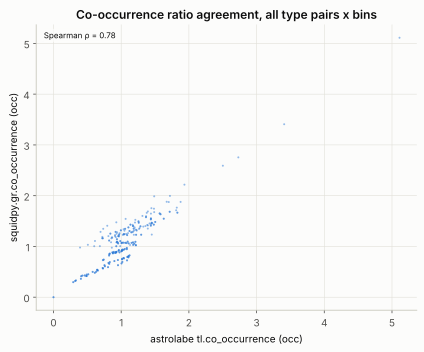

In [4]:
astro_vals = occ_astro.ravel()
ref_vals = occ_ref.ravel()

r = np.corrcoef(astro_vals, ref_vals)[0, 1]
from scipy.stats import spearmanr
rho = spearmanr(astro_vals, ref_vals).statistic
print(f"Pearson r = {r:.4f}, Spearman rho = {rho:.4f}")
print(f"Runtime: astrolabe {t_astro_s:.4f}s vs squidpy {t_ref_s:.4f}s "
      f"({max(t_astro_s, t_ref_s) / min(t_astro_s, t_ref_s):.1f}x astrolabe {'faster' if t_astro_s < t_ref_s else 'slower'}) -- "
      f"squidpy's kernel is numba-JIT-compiled, so its *first* call in a fresh kernel includes "
      f"one-time compilation overhead not representative of steady-state speed.")

panel = ab.pl.scatter(
    adata, x=astro_vals, y=ref_vals, annotate_corr=True,
    xlabel="astrolabe tl.co_occurrence (occ)", ylabel="squidpy.gr.co_occurrence (occ)",
    title="Co-occurrence ratio agreement, all type pairs x bins",
)
panel.show()


## Interpretation

`tl.co_occurrence` now computes the ring-local marginal the same way squidpy
does (each type's share of the ring's own total, not the whole tissue's), so
the two matrices should agree closely: expect a strong Pearson correlation
and a largely symmetric matrix, limited mainly by the residual bin-edge
convention noted above.
